# 12. EP3: optimización de hiperparámetros y ensambles (IE9 e IE10)

**IE9.** Cada modelo (LR, RF, HGB, XGBoost, LightGBM) se compara **por defecto** contra **optimizado** con una búsqueda aleatoria **anidada**: la búsqueda se hace solo con los segmentos de entrenamiento de cada fold externo, así que el fold de validación nunca influye en la elección de hiperparámetros. "Mejora" significa una diferencia de PR-AUC fuera de fold de al menos +0,010 con IC pareado por segmentos que excluya 0.

**IE10.** Ensambles E1 a E4. Uno "aporta" si supera en al menos 0,010 de AUC a su mejor componente y el IC pareado excluye 0.

**Analogía.** Afinar hiperparámetros es ajustar la dificultad de un examen de práctica con un profesor distinto cada vez; un ensamble es consultar a varios compañeros y promediar. Solo sirve si los compañeros se equivocan en cosas distintas.

**Desviación registrada (DEV-1):** por tiempo de cómputo se usó 1 repetición de la CV externa (semilla 42) y 30 configuraciones (el plan decía 3 y 40). Ver `docs/ep3/plan_v3_desviaciones.md`.

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists()), Path("C:/Users/maico/waymo-evaluacion"))
sys.path.insert(0, str(RAIZ / "src"))
REP, IMG, APP = RAIZ / "data/08_reporting_ep3", RAIZ / "images/ep3", RAIZ / "data/09_app_ep3"
IMG.mkdir(parents=True, exist_ok=True)
RECALCULAR = False          # True: vuelve a correr los scripts de esta fase (puede tardar mucho; escribe solo en *_ep3)
SEMILLA = 42
EN_MUESTRA = "en muestra: 41 segmentos, parámetros del detector ajustados con los mismos datos; post hoc, no pre-declarado; sin validación con datos nuevos"
GANANCIA_C = "La ganancia del brazo C sale de 2 celdas cámara x segmento, una de ellas en el segmento donde se descubrió el hueco."
AZUL, NARANJA, GRIS, VERDE, ROJO = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e", "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

from waymo_evaluacion.ep3.plan import verificar_plan_v3
print("Plan v3 verificado (sha256):", ", ".join(verificar_plan_v3(RAIZ)))


def coma(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


def miles(x):
    return f"{int(round(x)):,}".replace(",", ".")


def guardar_fig(fig, nombre):
    fig.savefig(IMG / f"{nombre}.png", dpi=130, bbox_inches="tight")


def correr(script, *args):
    r = subprocess.run([sys.executable, "-X", "utf8", str(RAIZ / "scripts/ep3" / script), *args], capture_output=True, text=True, cwd=RAIZ)
    print(r.stdout[-1500:], r.stderr[-800:])
    assert r.returncode == 0, f"{script} fallo"

Plan v3 verificado (sha256): plan_v3.md, plan_v3.json


In [2]:
if RECALCULAR:      # tarda horas: RF ajusta 200 arboles por configuracion
    correr("f3_tuning.py", "--etapa", "principal", "--semillas", "42", "--ncfg", "30", "--workers", "6")
    correr("f3_analisis.py")
    correr("f4_ensambles.py", "--workers", "5")
t9 = pd.read_csv(REP / "f3_defecto_vs_optimizado.csv")
vista = pd.DataFrame({"modelo": t9["modelo"], "etapa": t9["etapa"]})
for k in ["PR-AUC", "AUC"]:
    vista[f"{k} defecto"] = [f"{coma(r[k + '_def'])}" for _, r in t9.iterrows()]
    vista[f"{k} optimizado"] = [f"{coma(r[k + '_opt'])}" for _, r in t9.iterrows()]
vista["dif. PR-AUC (IC 95 %)"] = [f"{coma(r['dif_PR-AUC'], 3)} ({coma(r['dif_PR-AUC_lo'])} a {coma(r['dif_PR-AUC_hi'])})" for _, r in t9.iterrows()]
vista["folds donde gana"] = t9["folds_opt_gana_ap"].astype(str) + " de 5"
vista["veredicto"] = t9["veredicto"]
display(vista)

,modelo,etapa,PR-AUC defecto,PR-AUC optimizado,AUC defecto,AUC optimizado,dif. PR-AUC (IC 95 %),folds donde gana,veredicto
0,LR,principal,"0,650","0,631","0,797","0,775","-0,018 (-0,051 a 0,018)",3 de 5,no mejora
1,RF,principal,"0,650","0,610","0,798","0,746","-0,040 (-0,077 a 0,003)",4 de 5,no mejora
2,HGB,principal,"0,636","0,650","0,794","0,772","0,014 (-0,021 a 0,047)",4 de 5,no mejora
3,XGB,principal,"0,619","0,677","0,791","0,800","0,059 (0,034 a 0,085)",5 de 5,mejora
4,LGBM,ext,"0,638","0,675","0,796","0,794","0,036 (0,012 a 0,060)",4 de 5,mejora


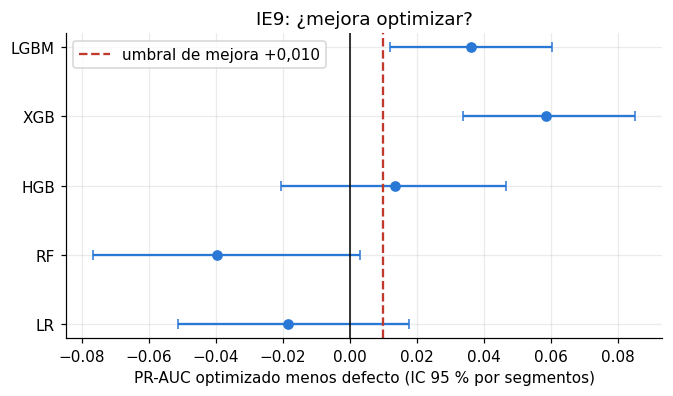

**Lectura (generada).** Mejoran con la búsqueda según el criterio del plan: XGB, LGBM. No mejoran: LR, RF, HGB. Un modelo puede ganar en el promedio y aun así 'no mejorar' si el IC incluye 0: con 41 segmentos y diferencias pequeñas, el intervalo manda.

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(t9))
ax.errorbar(t9["dif_PR-AUC"], y, xerr=[t9["dif_PR-AUC"] - t9["dif_PR-AUC_lo"], t9["dif_PR-AUC_hi"] - t9["dif_PR-AUC"]], fmt="o", color=AZUL, capsize=3)
ax.axvline(0, color="k", lw=1); ax.axvline(0.010, color=ROJO, ls="--", label="umbral de mejora +0,010")
ax.set_yticks(y, t9["modelo"]); ax.set_xlabel("PR-AUC optimizado menos defecto (IC 95 % por segmentos)"); ax.legend(); ax.set_title("IE9: ¿mejora optimizar?")
guardar_fig(fig, "12_ie9_mejora"); plt.show()
mej = t9[t9["veredicto"] == "mejora"]["modelo"].tolist()
no = t9[t9["veredicto"] != "mejora"]["modelo"].tolist()
display(Markdown(f"**Lectura (generada).** Mejoran con la búsqueda según el criterio del plan: {', '.join(mej) if mej else 'ninguno'}. No mejoran: {', '.join(no) if no else 'ninguno'}. "
                 "Un modelo puede ganar en el promedio y aun así 'no mejorar' si el IC incluye 0: con 41 segmentos y diferencias pequeñas, el intervalo manda."))

### Óptimos en el borde de la grilla y comprobación de regularización
En EP2 varios óptimos quedaron en el borde (HGB `max_leaf_nodes` 4 y `min_samples_leaf` 100; RF `min_samples_leaf` 200 y `max_features` sqrt). Aquí las grillas incluyen valores más regularizados, y si un óptimo cae en el borde se extiende la grilla una vez.

In [4]:
bd = pd.read_csv(REP / "f3_bordes.csv")
display(bd)
ext = json.loads((REP / "f3_bordes_extension.json").read_text(encoding="utf-8")) if (REP / "f3_bordes_extension.json").exists() else {}
hay_ext = sorted({p.name.split("_")[1] for p in (REP / "f3_ckpt").glob("ext_*.pkl")})
print("Modelos con óptimo en el borde en la etapa principal:", ext if ext else "ninguno")
print("Modelos para los que se repitió la búsqueda con grilla extendida:", hay_ext if hay_ext else "ninguno")
cfg = pd.read_csv(REP / "f3_config_por_fold.csv")
display(cfg.drop(columns=["etapa"]))

,modelo,etapa,hiperparametro,min_grilla,max_grilla,folds_en_min,folds_en_max,borde
0,LR,principal,C,0.00001,100.0,0,0,no
1,RF,principal,max_depth,3.00000,12.0,0,2,no
2,RF,principal,min_samples_leaf,20.00000,1600.0,0,0,no
3,HGB,principal,max_leaf_nodes,2.00000,15.0,0,1,no
4,HGB,principal,min_samples_leaf,20.00000,3200.0,0,0,no
5,HGB,principal,max_iter,30.00000,200.0,0,1,no
6,HGB,principal,max_depth,2.00000,4.0,2,1,no
7,XGB,principal,max_depth,1.00000,6.0,1,0,no
8,XGB,principal,min_child_weight,1.00000,300.0,1,0,no
9,XGB,principal,n_estimators,30.00000,200.0,2,1,no


Modelos con óptimo en el borde en la etapa principal: ninguno
Modelos para los que se repitió la búsqueda con grilla extendida: ['LGBM']


,modelo,fold,C,class_weight,variables,min_samples_leaf,max_features,max_depth,l2_regularization,learning_rate,max_iter,max_leaf_nodes,colsample_bytree,min_child_weight,n_estimators,reg_lambda,subsample,min_child_samples,num_leaves,subsample_freq
0,LR,0,0.010,NaN,V_OBS_TAM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LR,1,0.001,NaN,V_OBS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LR,2,0.001,NaN,V_OBS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LR,3,0.001,NaN,V_OBS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LR,4,0.001,balanced,V_OBS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,RF,0,NaN,NaN,V_OBS,400.0,2.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,RF,1,NaN,balanced,V_OBS,100.0,1.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,RF,2,NaN,balanced,V_OBS,800.0,2.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,RF,3,NaN,NaN,V_OBS_TAM,100.0,2.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,RF,4,NaN,balanced,V_OBS,800.0,0.3,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Curvas de validación (un hiperparámetro clave por modelo; el resto por defecto, conjunto V16)
Si la curva de entrenamiento sube y la de validación baja o se aplana, el modelo se está memorizando los segmentos de entrenamiento.

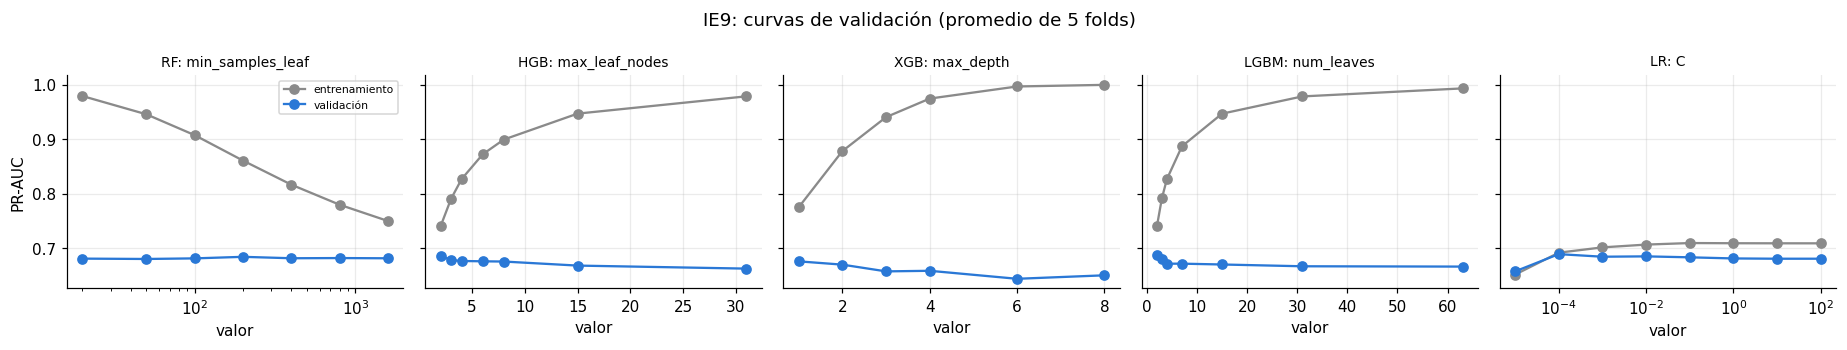

In [5]:
if (REP / "f3_curvas_validacion.csv").exists():
    cv = pd.read_csv(REP / "f3_curvas_validacion.csv")
    modelos = list(cv["modelo"].unique())
    fig, axes = plt.subplots(1, len(modelos), figsize=(3.4 * len(modelos), 3.2), sharey=True)
    for ax, m in zip(np.atleast_1d(axes), modelos):
        d = cv[cv["modelo"] == m].groupby("valor")[["ap_train", "ap_val"]].mean().sort_index()
        ax.plot(d.index, d["ap_train"], "o-", color=GRIS, label="entrenamiento"); ax.plot(d.index, d["ap_val"], "o-", color=AZUL, label="validación")
        if m in ("LR", "RF"):
            ax.set_xscale("log")
        ax.set_title(f"{m}: {cv[cv['modelo'] == m]['hiperparametro'].iloc[0]}", fontsize=9); ax.set_xlabel("valor")
    np.atleast_1d(axes)[0].set_ylabel("PR-AUC"); np.atleast_1d(axes)[0].legend(fontsize=7)
    fig.suptitle("IE9: curvas de validación (promedio de 5 folds)"); fig.tight_layout(); guardar_fig(fig, "12_ie9_curvas_validacion"); plt.show()
else:
    print("Las curvas de validación aún no se calcularon (scripts/ep3/f3_tuning.py --etapa curvas).")

## IE10: ensambles
Los modelos base de los ensambles usan la configuración optimizada solo si IE9 dio 'mejora' para ese modelo; si no, el defecto.

,ensamble,mejor componente,AUC ensamble,AUC mejor comp.,diferencia (IC 95 %),folds ganados,segmentos ganados,veredicto
0,E1,RF,"0,803","0,798","0,005 (-0,007 a 0,020)",3 de 5,21 de 31,no aporta
1,E2,Regla top,"0,824","0,823","0,001 (-0,005 a 0,008)",5 de 5,20 de 31,no aporta
2,E3,XGB,"0,789","0,800","-0,011 (-0,021 a -0,000)",1 de 5,13 de 31,no aporta
3,E4,vista_obs,"0,773","0,792","-0,019 (-0,038 a -0,003)",1 de 5,10 de 31,no aporta


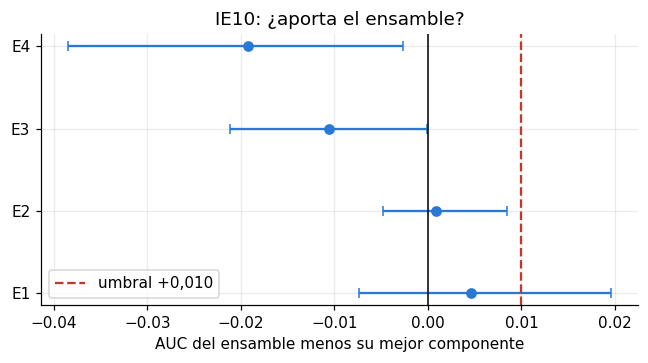

**Lectura (generada).** Aportan: ninguno. Indicio no concluyente: ninguno. El ensamble principal declarado en el plan (mayor AUC entre E1 y E4) es **E1**.

In [6]:
t10 = pd.read_csv(REP / "f4_ensambles_aporta.csv")
v10 = pd.DataFrame({"ensamble": t10["ensamble"], "mejor componente": t10["mejor_componente"], "AUC ensamble": t10["AUC_ensamble"].map(coma), "AUC mejor comp.": t10["AUC_mejor_componente"].map(coma),
                    "diferencia (IC 95 %)": [f"{coma(r.dif_AUC)} ({coma(r.dif_lo)} a {coma(r.dif_hi)})" for r in t10.itertuples()],
                    "folds ganados": t10["folds_ganados_de_5"].astype(str) + " de 5", "segmentos ganados": t10["segmentos_ganados"].astype(str) + " de " + t10["segmentos_comparados"].astype(str),
                    "veredicto": t10["veredicto"]})
display(v10)
fig, ax = plt.subplots(figsize=(7, 3.2))
y = np.arange(len(t10))
ax.errorbar(t10["dif_AUC"], y, xerr=[t10["dif_AUC"] - t10["dif_lo"], t10["dif_hi"] - t10["dif_AUC"]], fmt="o", color=AZUL, capsize=3)
ax.axvline(0, color="k", lw=1); ax.axvline(0.010, color=ROJO, ls="--", label="umbral +0,010")
ax.set_yticks(y, t10["ensamble"]); ax.set_xlabel("AUC del ensamble menos su mejor componente"); ax.legend(); ax.set_title("IE10: ¿aporta el ensamble?")
guardar_fig(fig, "12_ie10_aporta"); plt.show()
res4 = json.loads((REP / "f4_resumen.json").read_text(encoding="utf-8"))
ap = t10[t10["veredicto"] == "aporta"]["ensamble"].tolist(); ind = t10[t10["veredicto"] == "indicio no concluyente"]["ensamble"].tolist()
display(Markdown(f"**Lectura (generada).** Aportan: {', '.join(ap) if ap else 'ninguno'}. Indicio no concluyente: {', '.join(ind) if ind else 'ninguno'}. "
                 f"El ensamble principal declarado en el plan (mayor AUC entre E1 y E4) es **{res4['ensamble_principal_declarado']}**."))

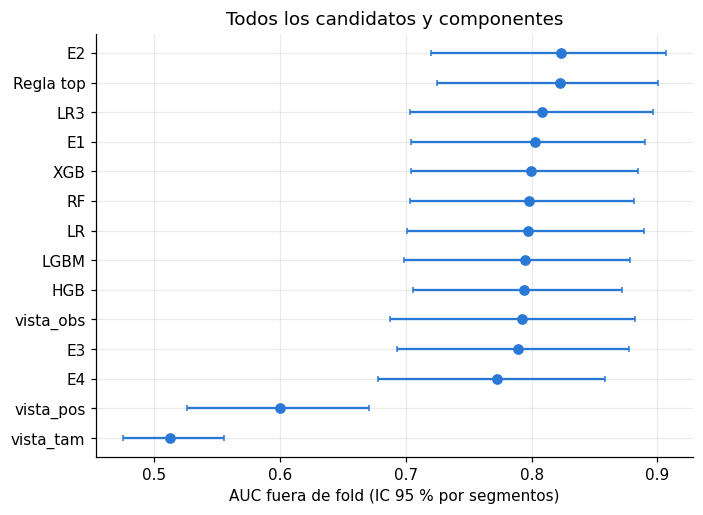

**Cuidado al leer.** Los IC de cada candidato se solapan mucho porque comparten los mismos 41 segmentos; lo que decide es la diferencia **pareada**, no el solapamiento de las barras.

In [7]:
cand = pd.read_csv(REP / "f4_candidatos_metricas.csv")
orden = cand.sort_values("AUC")
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(orden["AUC"], range(len(orden)), xerr=[orden["AUC"] - orden["AUC_lo"], orden["AUC_hi"] - orden["AUC"]], fmt="o", color=AZUL, capsize=2)
ax.set_yticks(range(len(orden)), orden["candidato"]); ax.set_xlabel("AUC fuera de fold (IC 95 % por segmentos)"); ax.set_title("Todos los candidatos y componentes")
guardar_fig(fig, "12_candidatos_auc"); plt.show()
display(Markdown("**Cuidado al leer.** Los IC de cada candidato se solapan mucho porque comparten los mismos 41 segmentos; lo que decide es la diferencia **pareada**, no el solapamiento de las barras."))

**Sobre por qué LR y RF empeoran al optimizar: hipótesis, no verificada.** Con 41 segmentos y 30 configuraciones, la búsqueda interna puede elegir configuraciones que aprovechan particularidades de los segmentos de entrenamiento y no se sostienen en el fold de validación (sobreajuste de la búsqueda); en LR, el criterio interno (PR-AUC) podría preferir variables y regularización distintas de las que sirven en el fold externo. No lo probamos.

**Desviación DEV-1:** 1 repetición y 30 configuraciones por la regla de cómputo (ver `plan_v3_desviaciones.md`).